## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load Dataset


In [2]:
df=pd.read_csv('D:\Day-3-task-Elevate-Lab---Nishita-kanojiya\dataset\Housing.csv')
df

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Nishita\AppData\Local\Temp\ipykernel_7084\3771189522.py:1: SyntaxWarning: invalid escape sequence '\D'
  df=pd.read_csv('D:\Day-3-task-Elevate-Lab---Nishita-kanojiya\dataset\Housing.csv')


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [3]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [4]:
df.tail()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


## 3. Understand the data

In [5]:
print('Shape:', df.shape)
print('\nColumns:', df.columns.tolist())
print('\nData types:')
display(df.dtypes)
print('\nMissing values:')
display(df.isnull().sum())
print('\nSummary statistics:')
display(df.describe(include='all').T)

Shape: (545, 13)

Columns: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Data types:


price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object


Missing values:


price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,545.0,NaN,NaN,NaN,4766729.247706,1870439.615657,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,NaN,NaN,NaN,5150.541284,2170.141023,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,NaN,NaN,NaN,2.965138,0.738064,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,NaN,NaN,NaN,1.286239,0.50247,1.0,1.0,1.0,2.0,4.0
stories,545.0,NaN,NaN,NaN,1.805505,0.867492,1.0,1.0,2.0,2.0,4.0
mainroad,545,2,yes,468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
guestroom,545,2,no,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
basement,545,2,no,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotwaterheating,545,2,no,520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
airconditioning,545,2,no,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Preprocess the Data



In [6]:

numeric_df = df.select_dtypes(include=np.number)


numeric_df = numeric_df.dropna()

# Separate features and target
X = numeric_df.drop("price", axis=1)
y = numeric_df["price"]

print("Target: price")
print("Features:", X.columns.tolist())
print("Rows after preprocessing:", len(numeric_df))

Target: price
Features: ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Rows after preprocessing: 545


## 5. Train-Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))

Training samples: 436
Testing samples: 109


## 6. Train Multiple Linear Regression Model

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print('Model trained successfully.')
print('Intercept:', model.intercept_)

Model trained successfully.
Intercept: 51999.67680883687


## 7. Evaluate the Model

- **MAE:** Average absolute prediction error.
- **MSE:** Average squared prediction error.
- **R²:** Proportion of target variance explained by the model.

In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'MAE  : {mae:.2f}')
print(f'MSE  : {mse:.2f}')
print(f'RMSE : {rmse:.2f}')
print(f'R²   : {r2:.4f}')

MAE  : 1127483.35
MSE  : 2292721545725.36
RMSE : 1514173.55
R²   : 0.5464


## 8. Interpret Model Coefficients



In [10]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', key=lambda s: s.abs(), ascending=False)

display(coefficients)
print('Intercept:', model.intercept_)

,Feature,Coefficient
2,bathrooms,1.185732e+06
3,stories,4.951008e+05
4,parking,3.376608e+05
1,bedrooms,1.512468e+05
0,area,3.088670e+02


Intercept: 51999.67680883687


## 9. Actual vs Predicted Values

In [11]:
comparison = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
display(comparison.head(10))

,Actual,Predicted
0,4060000,6.178628e+06
1,6650000,6.370141e+06
2,3710000,3.283148e+06
3,6440000,4.226008e+06
4,2800000,3.409686e+06
5,4900000,4.262158e+06
6,5250000,5.493441e+06
7,4543000,5.559898e+06
8,2450000,3.373715e+06
9,3353000,3.020513e+06


## 10. Actual vs Predicted Plot



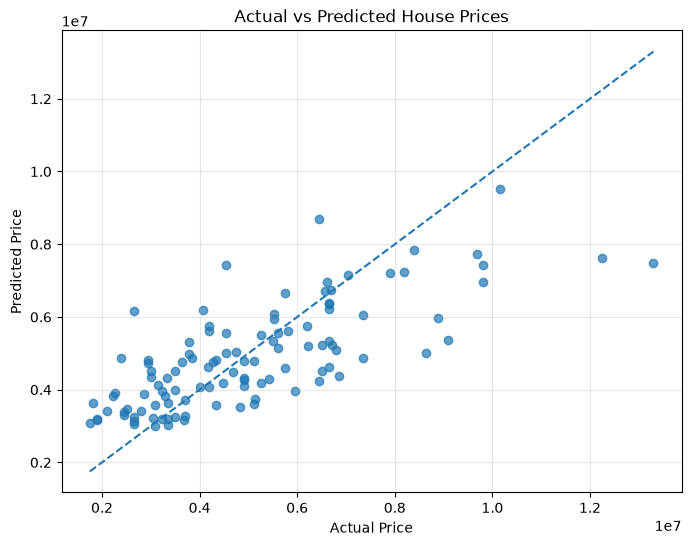

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle='--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.grid(True, alpha=0.3)
plt.show()



## 11. Simple Linear Regression



In [13]:
simple_feature = X.columns[0]
X_simple = X[[simple_feature]]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)
y_pred_s = simple_model.predict(X_test_s)

print('Feature used:', simple_feature)
print(f'Simple Linear Regression R²: {r2_score(y_test_s, y_pred_s):.4f}')

Feature used: area
Simple Linear Regression R²: 0.2729


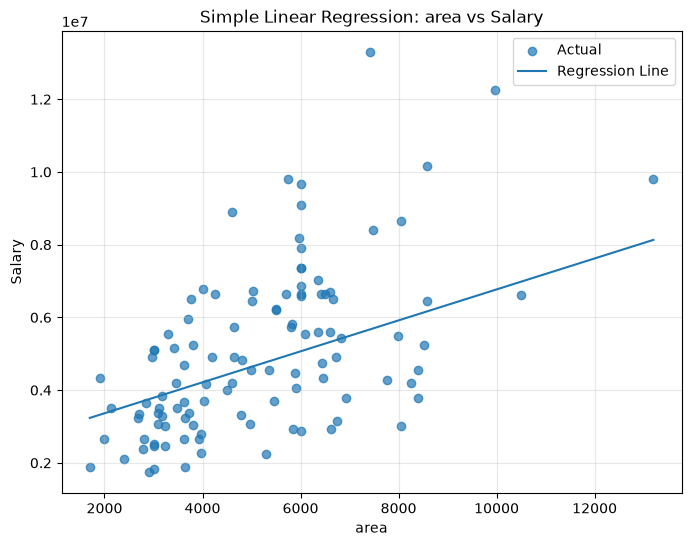

In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Define target column
TARGET_COLUMN = "Salary"  # Replace with your actual target column

# Create output folder
os.makedirs("../outputs", exist_ok=True)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_test_s[simple_feature],
    y_test_s,
    alpha=0.7,
    label="Actual"
)

order = np.argsort(X_test_s[simple_feature].values)

x_sorted = X_test_s[simple_feature].values[order]
y_sorted = y_pred_s[order]

plt.plot(
    x_sorted,
    y_sorted,
    label="Regression Line"
)

plt.xlabel(simple_feature)
plt.ylabel(TARGET_COLUMN)

plt.title(
    f"Simple Linear Regression: {simple_feature} vs {TARGET_COLUMN}"
)

plt.legend()
plt.grid(True, alpha=0.3)

# Save figure
plt.savefig(
    "../outputs/simple_linear_regression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. Final Interpretation

- The model learns the relationship between numerical features and house price.
- MAE shows average absolute prediction error.
- MSE penalizes larger errors more strongly.
- R² indicates how much target variation is explained by the model.
- Coefficients show feature contribution while other features are held constant.
- Simple regression uses one feature; multiple regression uses two or more features.